Số lượng dòng trùng lặp phát hiện: 30
Kích thước sau khi làm sạch: (1498, 7)


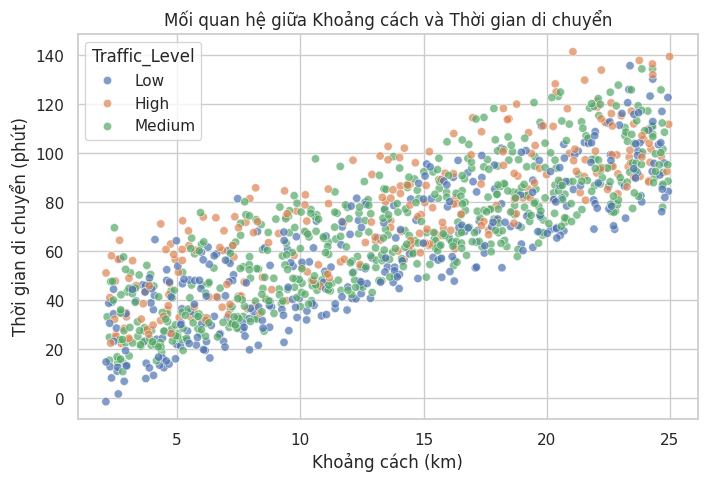

Bảng đánh giá hiệu năng các mô hình:
                               MAE       RMSE  R2 Score
Linear Regression        11.639962  13.308231  0.787507
Ridge Regression (L2)    11.644938  13.315365  0.787279
Random Forest Regressor   5.867978   7.980557  0.923586


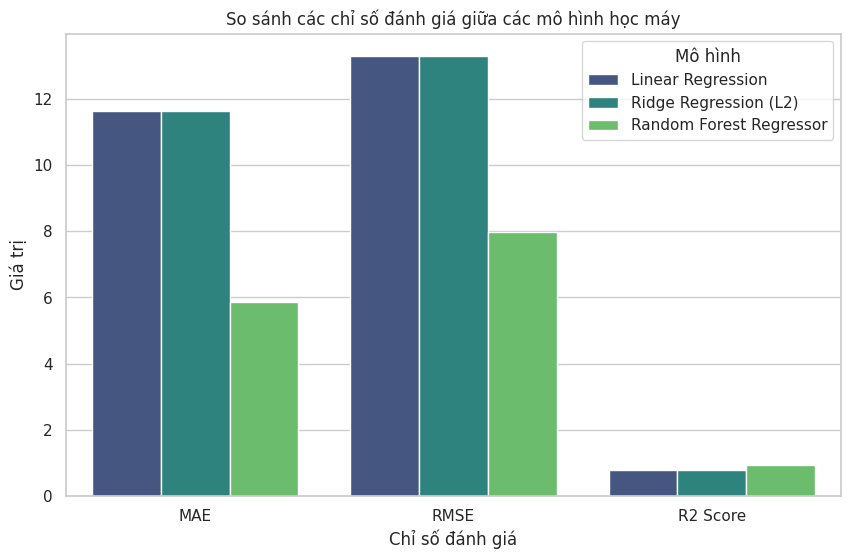

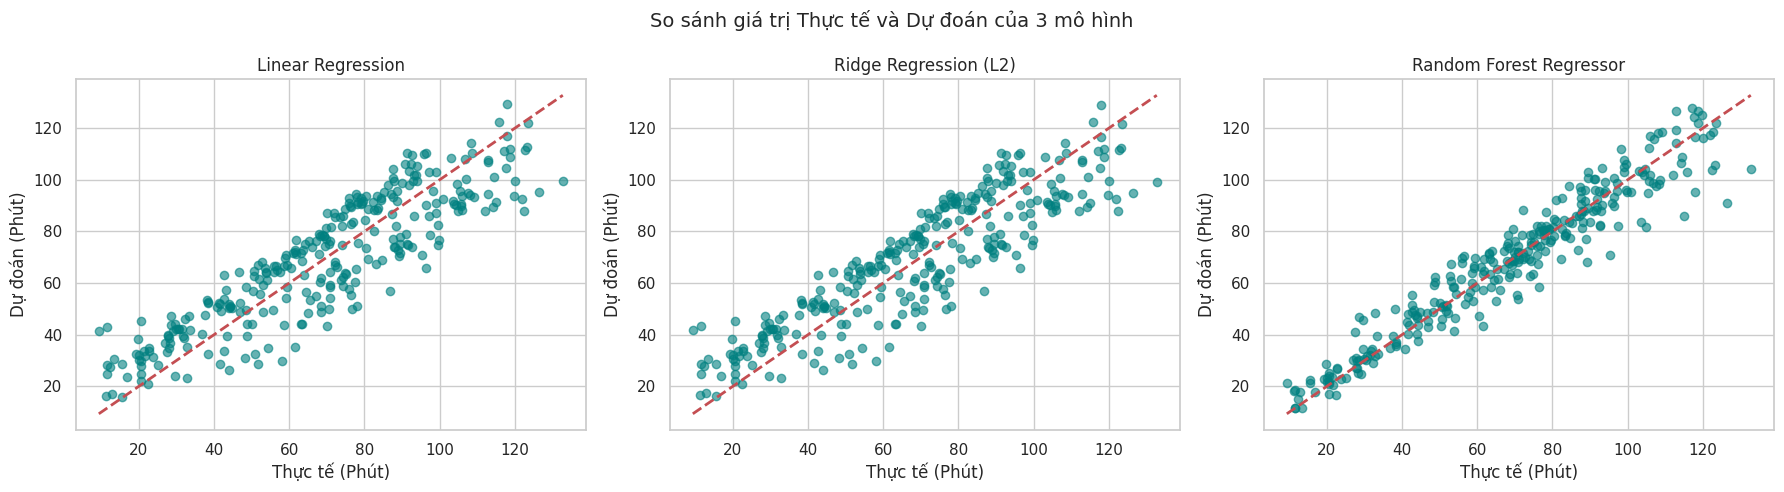

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

df = pd.read_csv('/data.csv')

# Bước 1: Xử lý dữ liệu
n_dups = df.duplicated().sum()
print(f"Số lượng dòng trùng lặp phát hiện: {n_dups}")
df = df.drop_duplicates().reset_index(drop=True)

df['Weather'] = df['Weather'].astype(str).str.strip().str.capitalize()
df['Weather'] = df['Weather'].replace({'Nan': np.nan, 'Rainy': 'Rainy'})

df = df[df['Distance_KM'].isna() | (df['Distance_KM'] > 0)]
df = df[df['Travel_Time_Min'] < 200]

print(f"Kích thước sau khi làm sạch: {df.shape}")

X = df.drop(columns=['Travel_Time_Min'])
y = df['Travel_Time_Min']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Bước 2: Phân tích khám phá dữ liệu (EDA)
train_eda = pd.concat([X_train, y_train], axis=1)

plt.figure(figsize=(8, 5))
sns.scatterplot(data=train_eda, x='Distance_KM', y='Travel_Time_Min', hue='Traffic_Level', alpha=0.7)
plt.title('Mối quan hệ giữa Khoảng cách và Thời gian di chuyển')
plt.xlabel('Khoảng cách (km)')
plt.ylabel('Thời gian di chuyển (phút)')
plt.show()

# Bước 3: Tiền xử lý đặc trưng với Pipeline
num_cols = ['Distance_KM', 'Num_Stops', 'Departure_Hour']
cat_cols = ['Day_Of_Week', 'Weather', 'Traffic_Level']

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ]
)

# Bước 4: Huấn luyện, đánh giá và lưu lại kết quả dự đoán của 3 mô hình
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression (L2)': Ridge(alpha=1.0),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=100, random_state=42)
}

results = {}
predictions = {}

for name, model in models.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])

    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results[name] = {'MAE': mae, 'RMSE': rmse, 'R2 Score': r2}

results_df = pd.DataFrame(results).T
print("Bảng đánh giá hiệu năng các mô hình:")
print(results_df)

# Bước 5: Trực quan hóa so sánh hiệu năng các mô hình (Bar Chart)
results_melted = results_df.reset_index().melt(id_vars='index', value_vars=['MAE', 'RMSE', 'R2 Score'])
results_melted.columns = ['Model', 'Metric', 'Value']

plt.figure(figsize=(10, 6))
sns.barplot(data=results_melted, x='Metric', y='Value', hue='Model', palette='viridis')
plt.title('So sánh các chỉ số đánh giá giữa các mô hình học máy')
plt.xlabel('Chỉ số đánh giá')
plt.ylabel('Giá trị')
plt.legend(title='Mô hình')
plt.show()

# Trực quan hóa lưới Actual vs Predicted cho cả 3 mô hìnhfig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (name, y_pred) in enumerate(predictions.items()):
    ax = axes[i]
    ax.scatter(y_test, y_pred, alpha=0.6, color='teal')
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    ax.set_title(f'{name}')
    ax.set_xlabel('Thực tế (Phút)')
    ax.set_ylabel('Dự đoán (Phút)')

plt.suptitle('So sánh giá trị Thực tế và Dự đoán của 3 mô hình', fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
